# ДЗ №1 СУНЦ МГУ - Numpy practice

**Среда:** Python 3.14.7. Локальные модули `functions.py` и `functions_vectorized.py` повторно импортируются при каждом запуске ячейки с решением.


### Туториальные задачи
__(9 баллов)__

Ниже приведены задачи на работу с numpy-массивами. Для каждой из задач нужно привести 2 реализации: одна без использования numpy (cчитайте, что там, где на входе или выходе должны быть numpy array, будут просто списки), а вторая полностью векторизованная (без использования питоновских циклов/map/list comprehension). Невекторизованная реализация каждой из задач оценивается в __0.5 балла__, векторизованная – в __1 балл__.

Реализации без использования векторизации нужно записать в файл functions.py, а векторизованные &mdash; в файл functions_vectorized.py

Для каждой задачи, приведённой ниже сравните скорость работы невекторизованной и векторизованной реализации. С помощью пакета matplotlib постройте графики времени работы в зависимости от размера данных. __Графики должны выглядеть опрятно!__ То есть должны быть подписаны оси, названия графиков, и т.д. Например, ниже представлены хороший и плохой графики:

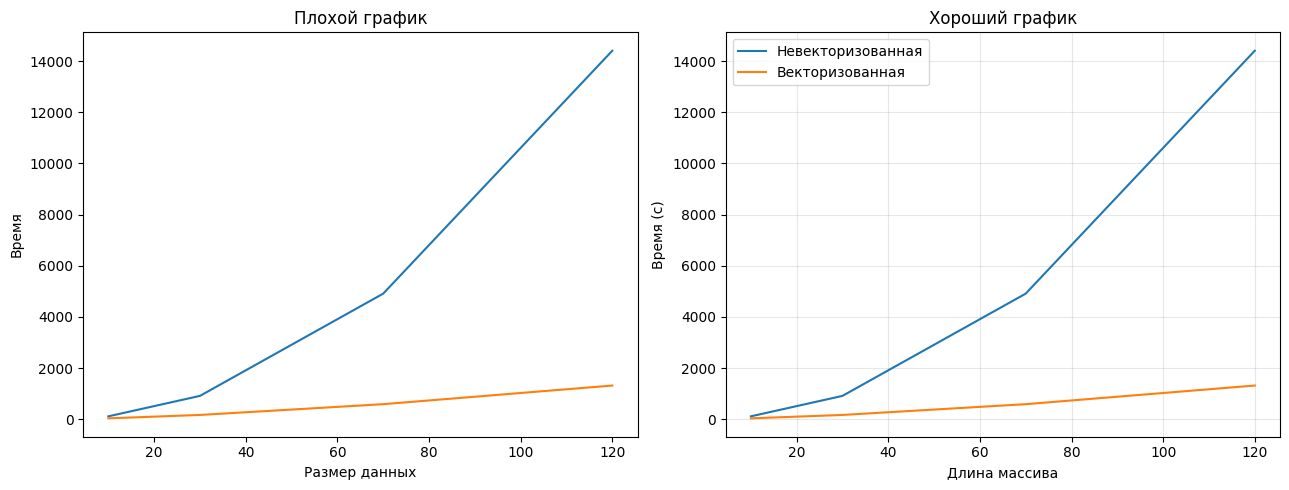

In [3]:
from importlib import reload
from scipy.spatial.distance import cdist
from PIL import Image

import matplotlib.pyplot as plt
import numpy as np

import time
import functions
import functions_vectorized

%matplotlib inline


def reload_solution_modules():
    """Reload the two local solution modules after their files change."""
    reload(functions)
    reload(functions_vectorized)


data_size = np.array([10, 30, 70, 120])
time_non_vectorized = data_size**2 + 10
time_vectorized = data_size**1.5

figure, (axis_bad, axis_good) = plt.subplots(1, 2, figsize=(13, 5))

axis_bad.plot(data_size, time_non_vectorized)
axis_bad.plot(data_size, time_vectorized)
axis_bad.set_title("Плохой график")
axis_bad.set_xlabel("Размер данных")
axis_bad.set_ylabel("Время")

axis_good.plot(data_size, time_non_vectorized, label="Невекторизованная")
axis_good.plot(data_size, time_vectorized, label="Векторизованная")
axis_good.set_title("Хороший график")
axis_good.set_xlabel("Длина массива")
axis_good.set_ylabel("Время (с)")
axis_good.grid(True, alpha=0.3)
axis_good.legend()

figure.tight_layout()
plt.show()


* __Задача 1__: Подсчитать произведение ненулевых элементов на диагонали прямоугольной матрицы.  
 Например, для X = np.array([[1, 0, 1], [2, 0, 2], [3, 0, 3], [4, 4, 4]]) ответ – 3.

C:\Users\Miron\OneDrive\Рабочий стол\task_numpy\functions.py:18: RuntimeWarning: overflow encountered in scalar multiply
  ans *= x[i][i]
C:\Users\Miron\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


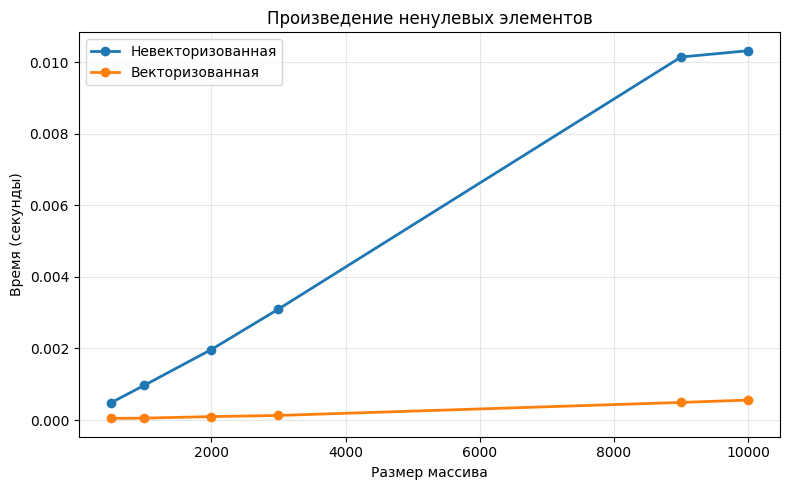

In [48]:
reload_solution_modules()

data_sizes = [500, 1000, 2000, 3000, 9000, 10000] 
time_non_vectorized = []
time_vectorized = []

num_tries = 3

for size in data_sizes:
    matrix = np.random.randint(0, 5, size=(size, size)).astype(np.float64)
    
    times_nv = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions.prod_non_zero_diag(matrix)
        times_nv.append(time.perf_counter() - start)
    time_non_vectorized.append(min(times_nv))
    
    times_v = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions_vectorized.prod_non_zero_diag(matrix)
        times_v.append(time.perf_counter() - start)
    time_vectorized.append(min(times_v))


plt.figure(figsize=(8, 5))
plt.plot(data_sizes, time_non_vectorized, label="Невекторизованная", marker='o', linewidth=2)
plt.plot(data_sizes, time_vectorized, label="Векторизованная", marker='o', linewidth=2)

plt.title("Произведение ненулевых элементов", fontsize=12)
plt.xlabel("Размер массива", fontsize=10)
plt.ylabel("Время (секунды)", fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

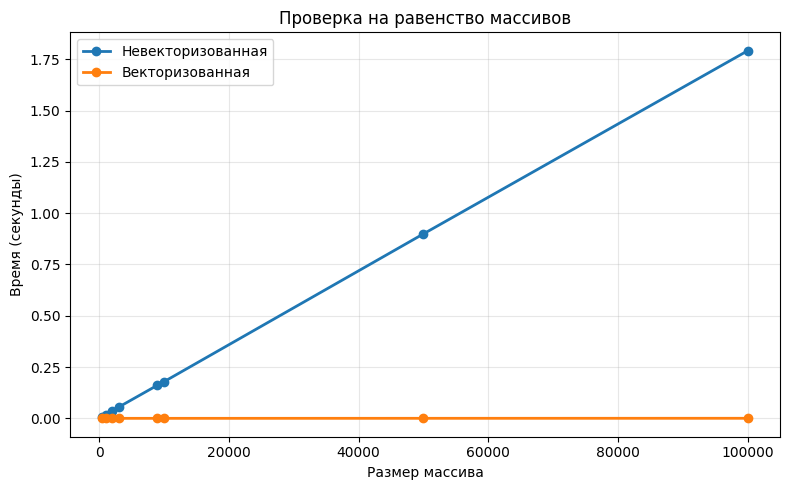

In [49]:
reload_solution_modules()

data_sizes = [500, 1000, 2000, 3000, 9000, 10000, 50000, 100000] 
time_non_vectorized = []
time_vectorized = []

num_tries = 3

for size in data_sizes:
    matrix1 = np.random.randint(0, 5, size=(size, 1)).astype(np.float64)
    matrix2 = np.random.randint(0, 5, size=(size, 1)).astype(np.float64)
    
    times_nv = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions.are_multisets_equal(matrix1, matrix2)
        times_nv.append(time.perf_counter() - start)
    time_non_vectorized.append(min(times_nv))
    
    times_v = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions_vectorized.are_multisets_equal(matrix1, matrix2)
        times_v.append(time.perf_counter() - start)
    time_vectorized.append(min(times_v))


plt.figure(figsize=(8, 5))
plt.plot(data_sizes, time_non_vectorized, label="Невекторизованная", marker='o', linewidth=2)
plt.plot(data_sizes, time_vectorized, label="Векторизованная", marker='o', linewidth=2)

plt.title("Проверка на равенство массивов", fontsize=12)
plt.xlabel("Размер массива", fontsize=10)
plt.ylabel("Время (секунды)", fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

* __Задача 3__: Найти максимальный элемент в векторе x среди элементов, перед которыми стоит нулевой.  
 Например, для x = np.array([6, 2, 0, 3, 0, 0, 5, 7, 0]) ответ – 5.

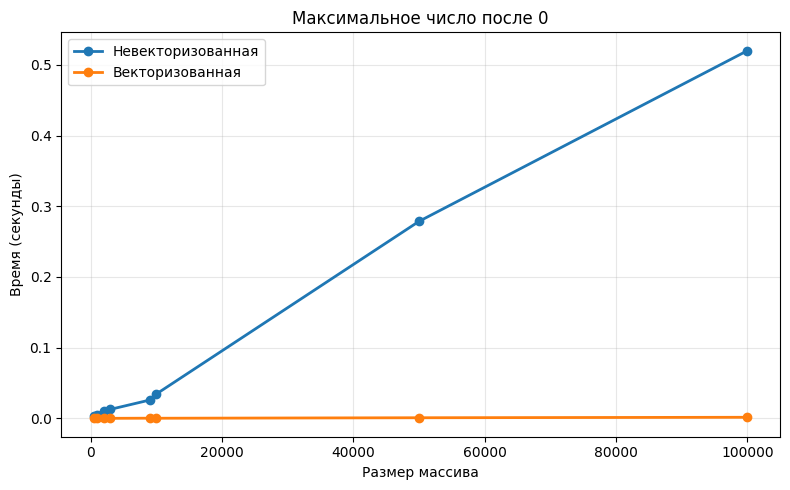

In [50]:
reload_solution_modules()


data_sizes = [500, 1000, 2000, 3000, 9000, 10000, 50000, 100000] 
time_non_vectorized = []
time_vectorized = []

num_tries = 3

for size in data_sizes:
    matrix1 = np.random.randint(0, 5, size=(size, 1)).astype(np.float64)
    
    times_nv = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions.max_after_zero(matrix1)
        times_nv.append(time.perf_counter() - start)
    time_non_vectorized.append(min(times_nv))
    
    times_v = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions_vectorized.max_after_zero(matrix1)
        times_v.append(time.perf_counter() - start)
    time_vectorized.append(min(times_v))


plt.figure(figsize=(8, 5))
plt.plot(data_sizes, time_non_vectorized, label="Невекторизованная", marker='o', linewidth=2)
plt.plot(data_sizes, time_vectorized, label="Векторизованная", marker='o', linewidth=2)

plt.title("Максимальное число после 0", fontsize=12)
plt.xlabel("Размер массива", fontsize=10)
plt.ylabel("Время (секунды)", fontsize=10)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

 
 
* __Задача 4__: Дан трёхмерный массив, содержащий изображение, размера (height, width, numChannels), а также вектор длины numChannels. Сложить каналы изображения с указанными весами, и вернуть результат в виде матрицы размера (height, width). В ноутбуке приведите пример работы функции – преобразуйте цветное изображение в оттенки серого, использовав коэффициенты np.array([0.299, 0.587, 0.114]). Считать реальное изображение можно с помощью `PIL.Image.open` из пакета Pillow: `img = np.asarray(Image.open(path).convert("RGB"))`. Устаревшая функция `scipy.misc.imread` удалена из современных версий SciPy.


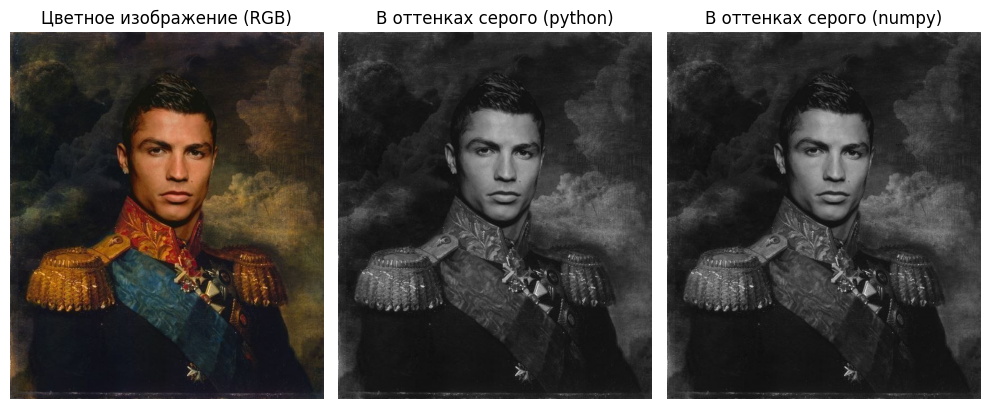

In [4]:
reload_solution_modules()

coefs = np.array([0.299, 0.587, 0.114])

path = "photo.jpg" 
img_pil = Image.open(path).convert("RGB")
img = np.asarray(img_pil, dtype=np.float64)

gray_img1 = functions.convert_image(img, coefs)
gray_img2 = functions_vectorized.convert_image(img, coefs)

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(img.astype(np.uint8))
plt.title("Цветное изображение (RGB)", fontsize=12)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gray_img1, cmap='gray')
plt.title("В оттенках серого (python)", fontsize=12)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(gray_img2, cmap='gray')
plt.title("В оттенках серого (numpy)", fontsize=12)
plt.axis('off')

plt.tight_layout()
plt.show()

* __Задача 5__: Реализовать кодирование длин серий (Run-length encoding). Для некоторого вектора x необходимо вернуть кортеж из двух векторов одинаковой длины. Первый содержит числа, а второй - сколько раз их нужно повторить.  
 Например, для x = np.array([2, 2, 2, 3, 3, 3, 5]) ответ – (np.array([2, 3, 5]), np.array([3, 3, 1])).

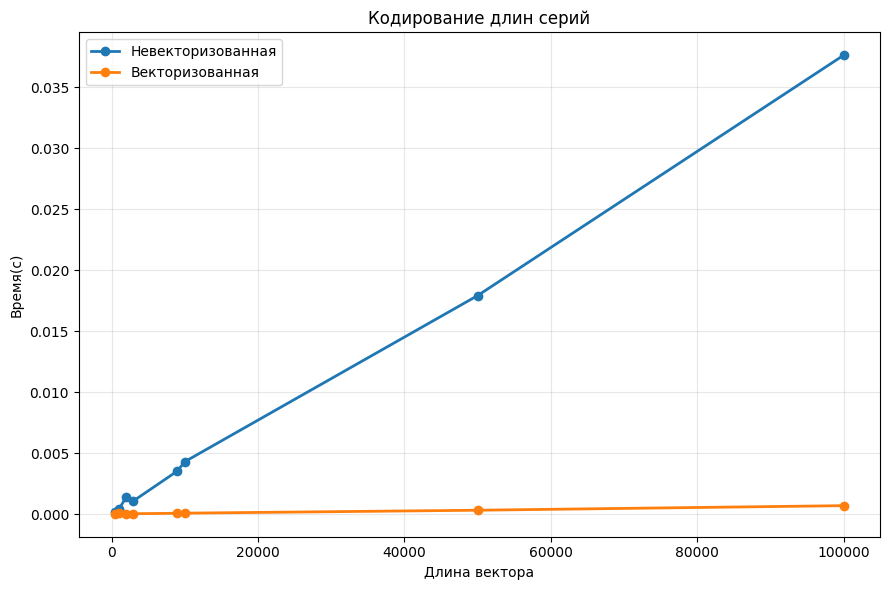

In [2]:
reload_solution_modules()

data_sizes = [500, 1000, 2000, 3000, 9000, 10000, 50000, 100000] 


time_non_vectorized = []
time_vectorized = []
num_tries = 3

for size in data_sizes:
    test_vector = np.random.randint(0, 10, size=size)
    
    times_nv = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions.run_length_encoding(test_vector)
        times_nv.append(time.perf_counter() - start)
    time_non_vectorized.append(min(times_nv))
    
    times_v = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions_vectorized.run_length_encoding(test_vector)
        times_v.append(time.perf_counter() - start)
    time_vectorized.append(min(times_v))

plt.figure(figsize=(9, 6))
plt.plot(data_sizes, time_non_vectorized, label="Невекторизованная", marker='o', linewidth=2)
plt.plot(data_sizes, time_vectorized, label="Векторизованная", marker='o', linewidth=2)

plt.title("Кодирование длин серий", fontsize=12)
plt.xlabel("Длина вектора", fontsize=10)
plt.ylabel("Время(с)", fontsize=10)
plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

 
 
* __Задача 6__: Даны две выборки объектов - X и Y. Вычислить матрицу евклидовых расстояний между объектами. Дополнительно сравните с функцией scipy.spatial.distance.cdist по скорости работы (сравнения приведите ниже в ноутбуке).

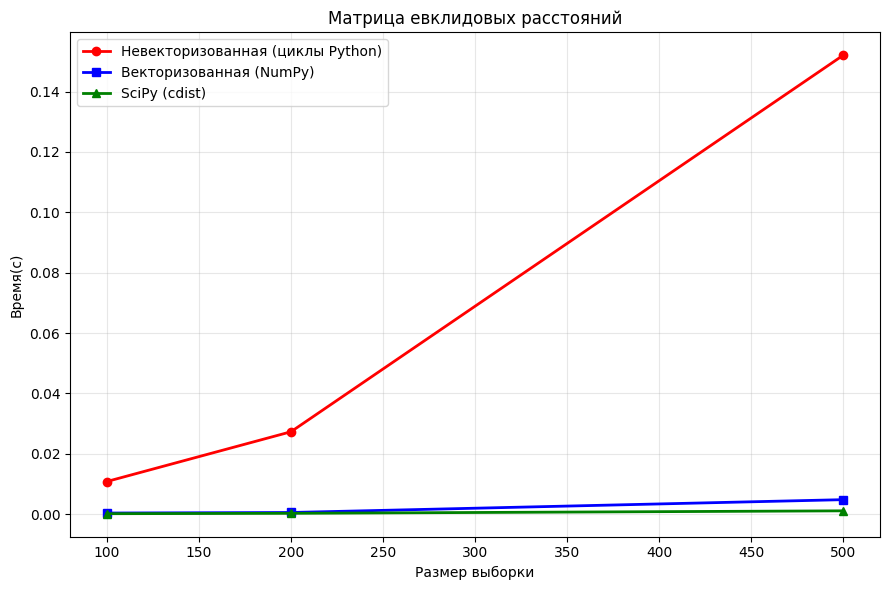

In [4]:
reload_solution_modules()

def pairwise_distances_scipy(X, Y):
    return cdist(X, Y, metric='euclidean')

data_sizes = [100, 200, 500]
D = 3

time_python = []
time_numpy = []
time_scipy = []

num_tries = 3

for n in data_sizes:
    X_np = np.random.randn(n, D)
    Y_np = np.random.randn(n, D)
    
    X_list = X_np.tolist()
    Y_list = Y_np.tolist()
    
    times_py = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions.pairwise_distance(X_list, Y_list)
        times_py.append(time.perf_counter() - start)
    time_python.append(min(times_py))
    
    times_np = []
    for _ in range(num_tries):
        start = time.perf_counter()
        functions_vectorized.pairwise_distance(X_np, Y_np)
        times_np.append(time.perf_counter() - start)
    time_numpy.append(min(times_np))
    
    times_sp = []
    for _ in range(num_tries):
        start = time.perf_counter()
        pairwise_distances_scipy(X_np, Y_np)
        times_sp.append(time.perf_counter() - start)
    time_scipy.append(min(times_sp))

plt.figure(figsize=(9, 6))

plt.plot(data_sizes, time_python, label="Невекторизованная (циклы Python)", marker='o', linewidth=2, color='red')
plt.plot(data_sizes, time_numpy, label="Векторизованная (NumPy)", marker='s', linewidth=2, color='blue')
plt.plot(data_sizes, time_scipy, label="SciPy (cdist)", marker='^', linewidth=2, color='green')

plt.title("Матрица евклидовых расстояний", fontsize=12)
plt.xlabel("Размер выборки", fontsize=10)
plt.ylabel("Время(c)", fontsize=10)
plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()

### Туториал по Markdown

__(1 балл)__

Напишите краткий (а в данной домашке ещё и почти бесмысленный) отчёт с использованием 4-5 различных вариантов разметки/выделения текста.

# code here

In [7]:
__hello__

NameError: name '__hello__' is not defined